In [ ]:
# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# 2. Create dataset
data = np.array([10, 20, 30, 40, 50, 60, 70, 80], dtype=float) / 100

X = []
y = []

In [ ]:
# 3. Prepare sequence data
for i in range(len(data) - 3):
    X.append(data[i:i+3])
    y.append(data[i+3])

X = np.array(X)
y = np.array(y)

In [ ]:
# 4. Initialize weights
np.random.seed(42)

Wx = np.random.randn() * 0.1
Wh = np.random.randn() * 0.1
Wy = np.random.randn() * 0.1

bh = 0.0
by = 0.0

lr = 0.05
losses = []


In [ ]:
# 5. Train RNN
for epoch in range(1000):

    total_loss = 0

    for seq, target in zip(X, y):

        h = 0.0

        # Forward propagation
        for x in seq:
            h = np.tanh(Wx * x + Wh * h + bh)

        output = Wy * h + by

        # Calculate error
        error = output - target
        total_loss += error ** 2

        # Backpropagation through time
        dy = 2 * error * Wy
        dh = dy * (1 - h ** 2)

        # Update weights
        Wy -= lr * (2 * error * h)
        by -= lr * (2 * error)

        Wx -= lr * dh * seq[-1]
        Wh -= lr * dh * h
        bh -= lr * dh

    losses.append(total_loss / len(X))


In [ ]:
# 6. Test RNN
test_sequence = np.array([60, 70, 80], dtype=float) / 100

h = 0.0

for x in test_sequence:
    h = np.tanh(Wx * x + Wh * h + bh)

prediction = Wy * h + by

print("Input Sequence:", test_sequence * 100)
print("Predicted Next Number:", round(prediction * 100, 2))

Input Sequence: [60. 70. 80.]
Predicted Next Number: 87.88


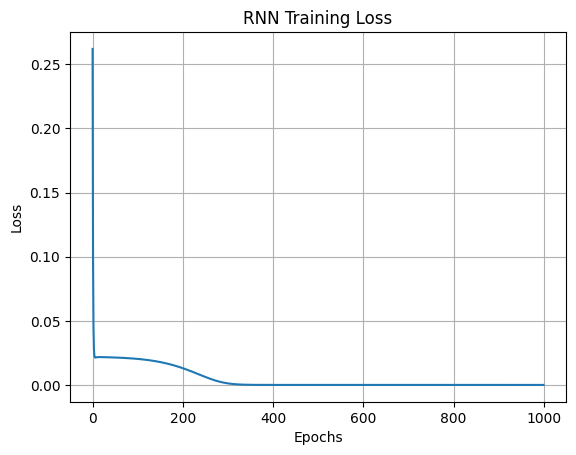

In [ ]:
# 7. Plot loss
plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("RNN Training Loss")
plt.grid()
plt.show()